# Transformation (Text Splitters / Chunking) - https://chunkviz.up.railway.app/

1. CHARACTER
2. Recursive
3. HTML
4. Markdown
5. Code
6. Token
7. Semantic 

### Loading the data

In [1]:
import os
os.getcwd()

'd:\\GenAI\\3rd_Oct_2025-20251004T070148Z-1-001\\3rd_Oct_2025'

In [3]:
!pip install langchain-openai
!pip install langchain-community

In [10]:
from langchain_community.document_loaders import TextLoader
loader = TextLoader("data\\text\\file_1.txt")
data = loader.load()
#print(data)
print(data[0].page_content)

This is pretty much
what's happened so far.

Ross was in love
with Rachel since forever.

Every time he tried to tell her,
something got in the way

Iike cats, Italian guys.

And finally, Chandler was,
like, "Forget about her."


In [11]:
doc_content = data[0].page_content
print(doc_content)

This is pretty much
what's happened so far.

Ross was in love
with Rachel since forever.

Every time he tried to tell her,
something got in the way

Iike cats, Italian guys.

And finally, Chandler was,
like, "Forget about her."


In [57]:
doc_content

'This is pretty much\nwhat\'s happened so far.\n\nRoss was in love\nwith Rachel since forever.\n\nEvery time he tried to tell her,\nsomething got in the way\n\nIike cats, Italian guys.\n\nAnd finally, Chandler was,\nlike, "Forget about her."'

### Split by Character - CharacterTextSplitter

In [22]:
from langchain_text_splitters import CharacterTextSplitter
text_splitter = CharacterTextSplitter(separator  = '\n\n',chunk_size=25, chunk_overlap=0)

In [27]:
chunks = text_splitter.split_text(doc_content)
print("Type of text variables", type(chunks))
print("**************************")
print("Type of each object inside the list", type(chunks[0]))
print("**************************")
print("Total number of documents inside the text", len(chunks))
print("**************************")
print("Content of first chunk", chunks[0])
print("**************************")
#print(doc_content)
#print(chunks)
print("Content of second chunk", chunks[1])
print("**************************")

Created a chunk of size 43, which is longer than the specified 25
Created a chunk of size 43, which is longer than the specified 25
Created a chunk of size 57, which is longer than the specified 25


Type of text variables <class 'list'>
**************************
Type of each object inside the list <class 'str'>
**************************
Total number of documents inside the text 5
**************************
Content of first chunk This is pretty much
what's happened so far.
**************************
Content of second chunk Ross was in love
with Rachel since forever.
**************************


In [49]:
print(len(chunks),'\n\n')
for chunk2 in chunks:
    print(len(chunk2))

5 


43
43
57
24
52


In [67]:
doc = "The International Day of Nonviolence is observed on Oct 2, MK Gandhi’s birthday. It encourages us to pledge ‘the universal relevance of the principle of nonviolence’ and the goal ‘to establish a culture of peace, tolerance, understanding, and nonviolence’. In fact, nonviolence is more powerful than the strongest weapon of destruction created by human beings.Nonviolence is considered a high human value across all castes and religions; for example, the Mahabharat contains multiple references to ahimsa paramo dharm , meaning that nonviolence is the greatest virtue. The Prophet of Islam said, God grants to nonviolence what he does not grant to violence, Sahih Muslim: 2593.In an era when violence frequently makes headlines, Gandhi’s legacy reminds us that lasting revolutions are won not on battlefields but in the realm of ideas. His philosophy not only changed the course of India’s independence movement but also provided the world with a model of resistance based on patience, tolerance, and moral courage.When Gandhi launched his nonviolent struggle, the British found themselves powerless. Accustomed to crushing violent revolts with force, they lost the moral ground. So baffled was one officer that he reportedly wired London: “Kindly advise how to kill atiger nonviolently.” Gandhi had moved the fight from battlefield to the moral realm, where the empire had no weapon.By 1947, India had gained its independence, but Gandhi’s contribution was far greater than just the political freedom of one country. He proved to the world that peace can be a more powerful force than war.Gandhi believed violence was the lowest use of human potential, while peace was the highest. Peace creates stability, freedom, and growth, whereas violence only breeds fear, suppresses creativity, and closes the door to progress.Austrian psychologist Alfred Adler once wrote that human beings alone possess the ability to “turn a minus into a plus”. Gandhi’s life embodied this truth. He showed that setbacks, when met with patience, tolerance and determination, could be turned into opportunities. Nonviolence, therefore, was not a passive retreat but an active use of human potential through discipline and restraint.“Where there is tolerance, peace prevails; where there is intolerance, war and chaos follow.” Gandhi’s principles remain just as relevant within families as they are between nations. Without tolerance, peace remains just an imaginable dream.“Peaceful revolution is the outcome of peaceful thinking,” Maulana Wahiduddin Khan wrote. According to him, Gandhi’s struggle was rooted in patience and forbearance. He believed that Gandhi had shown the world how truth could triumph without bloodshed.For Maulana, peace was not just desirable but intrinsic to human nature. “Man was born in peace. Man must die in peace. Peace is man’s birthright — God’s greatest blessing to humanity,” he said. In this sense, Gandhi’s legacy extended beyond India’s freedom movement. It was auniversal call for humanity to rediscover its natural state of harmony.Gandhi’s philosophy has since inspired many movements, from the American civil rights movement led by Martin Luther King Jr to Nelson Mandela’s fight against apartheid. Gandhi’s legacy of nonviolence endures as a reminder that peace, tolerance and moral courage remain the strongest forces for lasting change."

In [68]:
doc

'The International Day of Nonviolence is observed on Oct 2, MK Gandhi’s birthday. It encourages us to pledge ‘the universal relevance of the principle of nonviolence’ and the goal ‘to establish a culture of peace, tolerance, understanding, and nonviolence’. In fact, nonviolence is more powerful than the strongest weapon of destruction created by human beings.Nonviolence is considered a high human value across all castes and religions; for example, the Mahabharat contains multiple references to ahimsa paramo dharm , meaning that nonviolence is the greatest virtue. The Prophet of Islam said, God grants to nonviolence what he does not grant to violence, Sahih Muslim: 2593.In an era when violence frequently makes headlines, Gandhi’s legacy reminds us that lasting revolutions are won not on battlefields but in the realm of ideas. His philosophy not only changed the course of India’s independence movement but also provided the world with a model of resistance based on patience, tolerance, an

## RecursiveCharacterTextSplitter

In [54]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(separators  = ["\n\n","\n"," ",""],chunk_size=300, chunk_overlap=0)

In [55]:
texts = text_splitter.split_text(doc)
print(len(doc))
print(len(texts))

3358
12


In [61]:
text_splitter2 = RecursiveCharacterTextSplitter(separators  = ["\n\n","\n"," ",""],chunk_size=25, chunk_overlap=0)
text2 = text_splitter2.split_text(doc_content)
print(len(doc_content))
print(len(text2))
print("**************************"'\n'+"string Length/Chunk Length - ",str(len(doc_content))+"/"+str(25)+"="+str(len(doc_content)/25))

227
13
**************************
string Length/Chunk Length -  227/25=9.08


In [62]:
for text in text2:
    print(text)
    print(len(text))
    print()

This is pretty much
19

what's happened so far.
23

Ross was in love
16

with Rachel since
17

forever.
8

Every time he tried to
22

tell her,
9

something got in the way
24

Iike cats, Italian guys.
24

And finally, Chandler
21

was,
4

like, "Forget about
19

her."
5



In [71]:
3358/300

11.193333333333333

In [75]:
print(texts)

['The International Day of Nonviolence is observed on Oct 2, MK Gandhi’s birthday. It encourages us to pledge ‘the universal relevance of the principle of nonviolence’ and the goal ‘to establish a culture of peace, tolerance, understanding, and nonviolence’. In fact, nonviolence is more powerful than', 'the strongest weapon of destruction created by human beings.Nonviolence is considered a high human value across all castes and religions; for example, the Mahabharat contains multiple references to ahimsa paramo dharm , meaning that nonviolence is the greatest virtue. The Prophet of Islam said, God', 'grants to nonviolence what he does not grant to violence, Sahih Muslim: 2593.In an era when violence frequently makes headlines, Gandhi’s legacy reminds us that lasting revolutions are won not on battlefields but in the realm of ideas. His philosophy not only changed the course of India’s', 'independence movement but also provided the world with a model of resistance based on patience, tol

In [77]:
for text in texts:
    print(text)
    print(len(text))
    print()

The International Day of Nonviolence is observed on Oct 2, MK Gandhi’s birthday. It encourages us to pledge ‘the universal relevance of the principle of nonviolence’ and the goal ‘to establish a culture of peace, tolerance, understanding, and nonviolence’. In fact, nonviolence is more powerful than
299

the strongest weapon of destruction created by human beings.Nonviolence is considered a high human value across all castes and religions; for example, the Mahabharat contains multiple references to ahimsa paramo dharm , meaning that nonviolence is the greatest virtue. The Prophet of Islam said, God
299

grants to nonviolence what he does not grant to violence, Sahih Muslim: 2593.In an era when violence frequently makes headlines, Gandhi’s legacy reminds us that lasting revolutions are won not on battlefields but in the realm of ideas. His philosophy not only changed the course of India’s
289

independence movement but also provided the world with a model of resistance based on patience,

In [69]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(separators  = ["\n\n","\n"," ",""],chunk_size=300, chunk_overlap=100)
texts = text_splitter.split_text(doc)
print(len(doc))
print(len(texts))

3358
17


In [142]:
texts

['The International Day of Nonviolence is observed on Oct 2, MK Gandhi’s birthday. It encourages us to pledge ‘the universal relevance of the principle of nonviolence’ and the goal ‘to establish a culture of peace, tolerance, understanding, and nonviolence’. In fact, nonviolence is more powerful than',
 'of peace, tolerance, understanding, and nonviolence’. In fact, nonviolence is more powerful than the strongest weapon of destruction created by human beings.Nonviolence is considered a high human value across all castes and religions; for example, the Mahabharat contains multiple references to',
 'value across all castes and religions; for example, the Mahabharat contains multiple references to ahimsa paramo dharm , meaning that nonviolence is the greatest virtue. The Prophet of Islam said, God grants to nonviolence what he does not grant to violence, Sahih Muslim: 2593.In an era when',
 'God grants to nonviolence what he does not grant to violence, Sahih Muslim: 2593.In an era when vi

In [81]:
for text in texts:
    print(text)
    print(len(text))
    print()

The International Day of Nonviolence is observed on Oct 2, MK Gandhi’s birthday. It encourages us to pledge ‘the universal relevance of the principle of nonviolence’ and the goal ‘to establish a culture of peace, tolerance, understanding, and nonviolence’. In fact, nonviolence is more powerful than
299

of peace, tolerance, understanding, and nonviolence’. In fact, nonviolence is more powerful than the strongest weapon of destruction created by human beings.Nonviolence is considered a high human value across all castes and religions; for example, the Mahabharat contains multiple references to
294

value across all castes and religions; for example, the Mahabharat contains multiple references to ahimsa paramo dharm , meaning that nonviolence is the greatest virtue. The Prophet of Islam said, God grants to nonviolence what he does not grant to violence, Sahih Muslim: 2593.In an era when
292

God grants to nonviolence what he does not grant to violence, Sahih Muslim: 2593.In an era when v

# Code Splitters

In [70]:
from langchain_text_splitters import RecursiveCharacterTextSplitter, Language

python_code = """
def hello_world():
    print("Hello, World!")
hello_world()
"""

python_splitter = RecursiveCharacterTextSplitter.from_language(
    language=Language.PYTHON, chunk_size=50, chunk_overlap=0
)
python_docs = python_splitter.create_documents([python_code])
python_docs

[Document(metadata={}, page_content='def hello_world():\n    print("Hello, World!")'),
 Document(metadata={}, page_content='hello_world()')]

In [71]:
def hello_world():
    print("Hello, World!")
hello_world()

Hello, World!


# Markdown splitters

In [72]:
markdown_doc = """
# Team Introduction
hi, this is for testing

## Management Team
Hi, this is Sundram, the GenAI Trainer
Hi, this is Ross, the CEO

### Development Team
Hi, this is Richard, the Lead developer.
"""

# Team Introduction

## Management Team
Hi, this is Sundram, the GenAI Trainer
Hi, this is Ross, the CEO

### Development Team
Hi, this is Richard, the Lead developer.

In [102]:
from langchain_text_splitters import MarkdownHeaderTextSplitter
headers_to_split_on = [
    ("#", "Header 1"),
    ("##", "Header 2"),
    ("###", "Header 3"),]
markdown_splitter = MarkdownHeaderTextSplitter(headers_to_split_on)
md_header_splits = markdown_splitter.split_text(markdown_doc)
print(md_header_splits)

[Document(metadata={'Header 1': 'Team Introduction'}, page_content='hi, this is for testing'), Document(metadata={'Header 1': 'Team Introduction', 'Header 2': 'Management Team'}, page_content='Hi, this is Sundram, the GenAI Trainer\nHi, this is Ross, the CEO'), Document(metadata={'Header 1': 'Team Introduction', 'Header 2': 'Management Team', 'Header 3': 'Development Team'}, page_content='Hi, this is Richard, the Lead developer.')]


# TokenTextSplitter

In [74]:
from langchain_text_splitters import TokenTextSplitter
text_splitter = TokenTextSplitter(model_name="gpt-4o-mini",chunk_size=50, chunk_overlap=0)
docs = text_splitter.create_documents([doc])
len(docs)

14

In [75]:
docs

[Document(metadata={}, page_content='The International Day of Nonviolence is observed on Oct 2, MK Gandhi’s birthday. It encourages us to pledge ‘the universal relevance of the principle of nonviolence’ and the goal ‘to establish a culture of peace, tolerance, understanding'),
 Document(metadata={}, page_content=', and nonviolence’. In fact, nonviolence is more powerful than the strongest weapon of destruction created by human beings.Nonviolence is considered a high human value across all castes and religions; for example, the Mahabharat contains multiple'),
 Document(metadata={}, page_content=' references to ahimsa paramo dharm , meaning that nonviolence is the greatest virtue. The Prophet of Islam said, God grants to nonviolence what he does not grant to violence, Sahih Muslim: 2593.In an era'),
 Document(metadata={}, page_content=' when violence frequently makes headlines, Gandhi’s legacy reminds us that lasting revolutions are won not on battlefields but in the realm of ideas. His 

## tiktoken - very famous

In [77]:
!pip install tiktoken

In [76]:
import tiktoken
enc = tiktoken.encoding_for_model("gpt-4o-mini")
for d in docs:
    print("words:", len(d.page_content.split(' ')),
          "Tokens:", len(enc.encode(d.page_content)),
          "Chunk:",d.page_content)

words: 37 Tokens: 50 Chunk: The International Day of Nonviolence is observed on Oct 2, MK Gandhi’s birthday. It encourages us to pledge ‘the universal relevance of the principle of nonviolence’ and the goal ‘to establish a culture of peace, tolerance, understanding
words: 36 Tokens: 50 Chunk: , and nonviolence’. In fact, nonviolence is more powerful than the strongest weapon of destruction created by human beings.Nonviolence is considered a high human value across all castes and religions; for example, the Mahabharat contains multiple
words: 35 Tokens: 50 Chunk:  references to ahimsa paramo dharm , meaning that nonviolence is the greatest virtue. The Prophet of Islam said, God grants to nonviolence what he does not grant to violence, Sahih Muslim: 2593.In an era
words: 45 Tokens: 50 Chunk:  when violence frequently makes headlines, Gandhi’s legacy reminds us that lasting revolutions are won not on battlefields but in the realm of ideas. His philosophy not only changed the course of Ind

In [ ]:
import tiktoken
enc = tiktoken.encoding_for_model("gemini-2.5-pro")
enc

# Text_Embedding_Model

In [85]:
#f = open('keys/.openai_api_key.txt')
#OPENAI_API_KEY = f.read()
import os
from dotenv import load_dotenv
load_dotenv()
OPENAI_API_KEY = os.getenv('OPENAI_API_KEY')


In [86]:
from langchain_openai import OpenAIEmbeddings
embeddings_model = OpenAIEmbeddings(openai_api_key = OPENAI_API_KEY) # text_embedding_adda_002

# Embed Single Query 

In [124]:
embeded_query = embeddings_model.embed_query("What was the name mentioned in the conversation?")
print("Dimensionality of embedded vector :", len(embeded_query))
print(embeded_query[:50])

Dimensionality of embedded vector : 1536
[0.00541798397898674, -0.0006137302261777222, 0.03896196931600571, -0.0029515144415199757, -0.008955181576311588, 0.021130798384547234, -0.01718444563448429, -0.0017207544296979904, -0.0029960593674331903, -0.010459811426699162, 0.0224638469517231, 0.009159758687019348, 0.003946351353079081, -0.009344537742435932, -0.010070455260574818, 0.002885522088035941, 0.03642785921692848, 0.004296111408621073, 0.020536866039037704, -0.03230992704629898, -0.003230332862585783, -0.005609362386167049, 0.0015648470725864172, 0.02614622749388218, -0.01134411059319973, 0.01961296983063221, 0.02819199487566948, -0.018491098657250404, -0.002575357211753726, -0.01680169068276882, 0.011482695117592812, 0.0010187592124566436, -0.014742723666131496, 0.006830223370343447, -0.05094620957970619, -0.003923254087567329, 0.0055499691516160965, -0.017897166311740875, 0.026621373370289803, 0.004672268871217966, 0.022820206359028816, 0.0017471513710916042, -0.0053948867134749

In [126]:
embeded_query

[0.00541798397898674,
 -0.0006137302261777222,
 0.03896196931600571,
 -0.0029515144415199757,
 -0.008955181576311588,
 0.021130798384547234,
 -0.01718444563448429,
 -0.0017207544296979904,
 -0.0029960593674331903,
 -0.010459811426699162,
 0.0224638469517231,
 0.009159758687019348,
 0.003946351353079081,
 -0.009344537742435932,
 -0.010070455260574818,
 0.002885522088035941,
 0.03642785921692848,
 0.004296111408621073,
 0.020536866039037704,
 -0.03230992704629898,
 -0.003230332862585783,
 -0.005609362386167049,
 0.0015648470725864172,
 0.02614622749388218,
 -0.01134411059319973,
 0.01961296983063221,
 0.02819199487566948,
 -0.018491098657250404,
 -0.002575357211753726,
 -0.01680169068276882,
 0.011482695117592812,
 0.0010187592124566436,
 -0.014742723666131496,
 0.006830223370343447,
 -0.05094620957970619,
 -0.003923254087567329,
 0.0055499691516160965,
 -0.017897166311740875,
 0.026621373370289803,
 0.004672268871217966,
 0.022820206359028816,
 0.0017471513710916042,
 -0.005394886713474

In [148]:
len(embeded_query)

1536

# Embed list of texts

In [129]:
embeddings = embeddings_model.embed_documents(
    ["Hi there!", 
     "Oh, hello!",
     "What's your name please ?",
     "Hello World!",
     "My dear friends, please call me at 7pm for our casual discussion"])
print("Number of Embedding :", len(embeddings))
print("Dimentionality of Embedding :", len(embeddings[0]))
print("Dimentionality of Embedding :", len(embeddings[1]))
print("Dimentionality of Embedding :", len(embeddings[2]))
print("Dimentionality of Embedding :", len(embeddings[3]))
print("Dimentionality of Embedding :", len(embeddings[4]))

Number of Embedding : 5
Dimentionality of Embedding : 1536
Dimentionality of Embedding : 1536
Dimentionality of Embedding : 1536
Dimentionality of Embedding : 1536
Dimentionality of Embedding : 1536


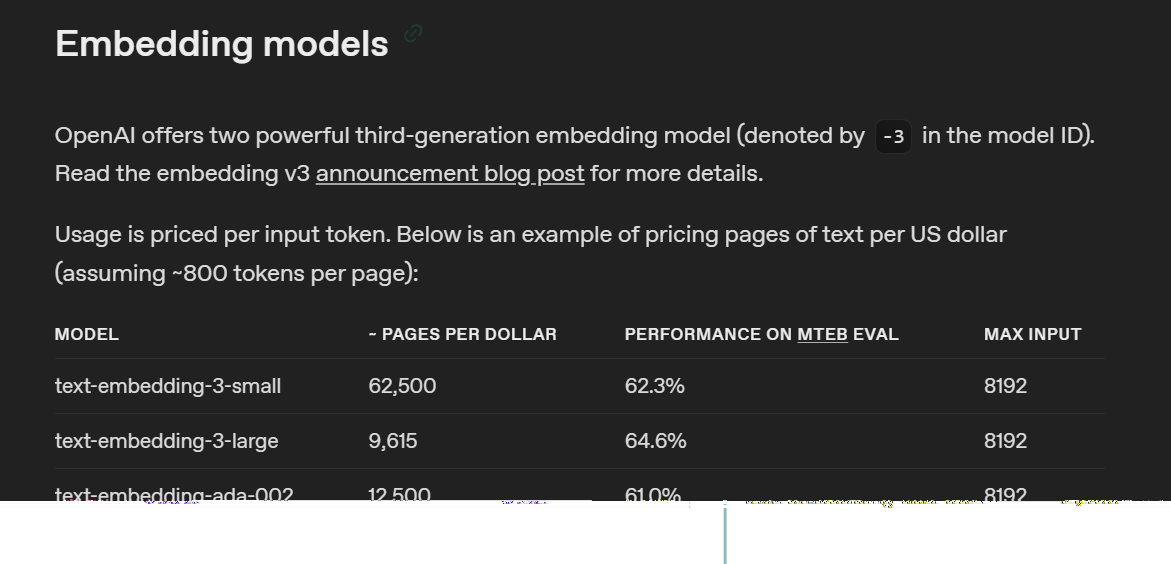

In [89]:
from langchain_openai import OpenAIEmbeddings
embeddings_model = OpenAIEmbeddings(openai_api_key = OPENAI_API_KEY, model="text-embedding-3-small")

In [144]:
embeddings = embeddings_model.embed_documents(texts)

In [ ]:
len(texts)


17

In [154]:
texts

['The International Day of Nonviolence is observed on Oct 2, MK Gandhi’s birthday. It encourages us to pledge ‘the universal relevance of the principle of nonviolence’ and the goal ‘to establish a culture of peace, tolerance, understanding, and nonviolence’. In fact, nonviolence is more powerful than',
 'of peace, tolerance, understanding, and nonviolence’. In fact, nonviolence is more powerful than the strongest weapon of destruction created by human beings.Nonviolence is considered a high human value across all castes and religions; for example, the Mahabharat contains multiple references to',
 'value across all castes and religions; for example, the Mahabharat contains multiple references to ahimsa paramo dharm , meaning that nonviolence is the greatest virtue. The Prophet of Islam said, God grants to nonviolence what he does not grant to violence, Sahih Muslim: 2593.In an era when',
 'God grants to nonviolence what he does not grant to violence, Sahih Muslim: 2593.In an era when vi

In [146]:
embeddings

[[0.0204412043094635,
  0.02945406176149845,
  0.0037748657632619143,
  0.011939110234379768,
  -0.03275274485349655,
  -0.011034632101655006,
  -0.002846445655450225,
  0.0007215872756205499,
  -0.04028651490807533,
  0.02251618355512619,
  0.015471895225346088,
  0.04877796769142151,
  -0.015972018241882324,
  -0.0326676182448864,
  0.0638880729675293,
  0.02924124337732792,
  -0.026900241151452065,
  -0.010124833323061466,
  0.012715897522866726,
  0.04198906198143959,
  0.014705749228596687,
  0.05256613716483116,
  0.006953840143978596,
  0.061504509299993515,
  0.0010261835996061563,
  -0.025580767542123795,
  0.0287304800003767,
  0.05763121321797371,
  0.010896299965679646,
  -0.0312204547226429,
  0.04622415080666542,
  -0.014375880360603333,
  -0.051587171852588654,
  -0.035412974655628204,
  0.029219960793852806,
  -0.03109276294708252,
  0.018791861832141876,
  -0.025793585926294327,
  -0.04920360445976257,
  0.03164609149098396,
  -0.037328340113162994,
  -0.08955396711826

In [150]:
len(embeddings)

17

# Vector Databases

In [88]:
!pip install langchain-chroma

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached requests_oauthlib-2.0.0-py2.py3-none-any.whl.metadata (11 kB)
  Using cached urllib3-2.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached googleapis_common_protos-1.70.0-py3-none-any.whl.metadata (9.3 kB)
  Using cached backoff-2.2.1-py3-none-any.whl.metadata (14 kB)
  Using cached pyasn1_modules-0.4.2-py3-none-any.whl.metadata (3.5 kB)
  Using cached rsa-4.9.1-py3-none-any.whl.metadata (5.6 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
  Using cached oauthlib-3.3.1-py3-none-any.whl.metadata (7.9 kB)
  Using cached pyasn1-0.6.1-py3-none-any.whl.metadata (8.4 kB)
   ---------------------------------------- 0.0/19.8 MB ? eta -

In [90]:
from langchain_chroma import Chroma

In [91]:
chroma_db = Chroma(collection_name="search_docs",embedding_function=embeddings_model,
                  persist_directory = "./chroma_db")

In [161]:
documents = ["Physics: The study of matter, energy, and the fundamental forces that govern the universe's behavior", 
"Maths: The abstract science of numbers, quantities, structures, and patterns that provides the language for describing logical relationships",
"Chemistry: The science of matter's composition, structure, properties, and the transformations it undergoes during chemical reactions",
"Biology: The study of living organisms, their structure, function, growth, evolution, and interactions with their environment",
"Photosynthesis: The process by which plants and other organisms convert light energy into chemical energy stored in glucose, releasing oxygen as a byproduct",       
"AI: The field of computer science focused on creating systems capable of performing tasks that typically require human intelligence, such as learning, reasoning, and problem-solving",
"GenAI: Artificial intelligence systems that can generate new content—including text, images, code, and audio—based on patterns learned from training data",
"Quantum Physics: The branch of physics that describes the behavior of matter and energy at atomic and subatomic scales, where particles exhibit wave-particle duality and probabilistic behavior"]

In [163]:
documents

["Physics: The study of matter, energy, and the fundamental forces that govern the universe's behavior",
 'Maths: The abstract science of numbers, quantities, structures, and patterns that provides the language for describing logical relationships',
 "Chemistry: The science of matter's composition, structure, properties, and the transformations it undergoes during chemical reactions",
 'Biology: The study of living organisms, their structure, function, growth, evolution, and interactions with their environment',
 'Photosynthesis: The process by which plants and other organisms convert light energy into chemical energy stored in glucose, releasing oxygen as a byproduct',
 'AI: The field of computer science focused on creating systems capable of performing tasks that typically require human intelligence, such as learning, reasoning, and problem-solving',
 'GenAI: Artificial intelligence systems that can generate new content—including text, images, code, and audio—based on patterns learne

In [165]:
ids = ['doc_'+str(i) for i in range(len(documents))]
ids

['doc_0', 'doc_1', 'doc_2', 'doc_3', 'doc_4', 'doc_5', 'doc_6', 'doc_7']

In [167]:
chroma_db.get()

{'ids': [],
 'embeddings': None,
 'metadatas': [],
 'documents': [],
 'uris': None,
 'data': None}

In [171]:
chroma_db.add_texts(texts=documents, ids=ids)

['doc_0', 'doc_1', 'doc_2', 'doc_3', 'doc_4', 'doc_5', 'doc_6', 'doc_7']

In [173]:
chroma_db.get()

{'ids': ['doc_0',
  'doc_1',
  'doc_2',
  'doc_3',
  'doc_4',
  'doc_5',
  'doc_6',
  'doc_7'],
 'embeddings': None,
 'metadatas': [None, None, None, None, None, None, None, None],
 'documents': ["Physics: The study of matter, energy, and the fundamental forces that govern the universe's behavior",
  'Maths: The abstract science of numbers, quantities, structures, and patterns that provides the language for describing logical relationships',
  "Chemistry: The science of matter's composition, structure, properties, and the transformations it undergoes during chemical reactions",
  'Biology: The study of living organisms, their structure, function, growth, evolution, and interactions with their environment',
  'Photosynthesis: The process by which plants and other organisms convert light energy into chemical energy stored in glucose, releasing oxygen as a byproduct',
  'AI: The field of computer science focused on creating systems capable of performing tasks that typically require human 

In [185]:
query = "Tell me about AI"
docs = chroma_db.similarity_search_with_score(query=query, k=1)
docs

[(Document(metadata={}, page_content='AI: The field of computer science focused on creating systems capable of performing tasks that typically require human intelligence, such as learning, reasoning, and problem-solving'),
  0.7544332120096173)]

In [187]:
query = "What is Maths"
docs = chroma_db.similarity_search_with_score(query=query, k=1)
docs

[(Document(metadata={}, page_content='Maths: The abstract science of numbers, quantities, structures, and patterns that provides the language for describing logical relationships'),
  0.8898068552615431)]

In [189]:
query = "How plant survive"
docs = chroma_db.similarity_search_with_score(query=query, k=1)
docs

[(Document(metadata={}, page_content='Photosynthesis: The process by which plants and other organisms convert light energy into chemical energy stored in glucose, releasing oxygen as a byproduct'),
  1.2875716728843525)]

In [191]:
texts

['The International Day of Nonviolence is observed on Oct 2, MK Gandhi’s birthday. It encourages us to pledge ‘the universal relevance of the principle of nonviolence’ and the goal ‘to establish a culture of peace, tolerance, understanding, and nonviolence’. In fact, nonviolence is more powerful than',
 'of peace, tolerance, understanding, and nonviolence’. In fact, nonviolence is more powerful than the strongest weapon of destruction created by human beings.Nonviolence is considered a high human value across all castes and religions; for example, the Mahabharat contains multiple references to',
 'value across all castes and religions; for example, the Mahabharat contains multiple references to ahimsa paramo dharm , meaning that nonviolence is the greatest virtue. The Prophet of Islam said, God grants to nonviolence what he does not grant to violence, Sahih Muslim: 2593.In an era when',
 'God grants to nonviolence what he does not grant to violence, Sahih Muslim: 2593.In an era when vi

In [93]:
chroma_db1 = Chroma(collection_name="doc_search",embedding_function=embeddings_model,
                  persist_directory = "./my_directory", collection_metadata = {"hnsw:space":"cosine"})

In [110]:
similarity_retriever = chroma_db1.as_retriever(search_type="similarity", 
                                               search_kwargs={'k':3})

In [199]:
chroma_db1.add_texts(texts=texts)

['a8930dd8-a177-46ee-985d-b60c9fbb961d',
 '4aef5a14-a479-4d68-aaba-9ad8c09e8254',
 'ae4df9df-a1dc-4e8b-83c2-e8e57c1dd1b1',
 'ada6d1a9-a954-4b64-b300-49a81766c12d',
 'ac8137d7-87a9-4526-bc69-15eb2d1dbab1',
 '91e3a922-c413-4ec4-bcb1-fb2fbfeee9b6',
 'a9d11e82-bebf-45fd-b674-296a9c309a1a',
 '8d5da294-6e63-423f-bdfc-32ff51b1706a',
 '53876c38-134d-40d2-8394-aceb507beb18',
 'c185591b-0b2c-4b94-9134-232a1bf9e971',
 '9bfff93d-c23b-4023-9577-a69e0bb21e04',
 '66894480-1ca9-4781-9c7c-90c13372da62',
 '77eba72c-725c-4bc2-a8d0-3a2268983cac',
 '39e7fa30-32e3-49c1-b7e1-f3e9357b6930',
 '7a76b394-d413-4cf7-b096-eccf50d2be53',
 '7c50cbff-0a04-4327-9f0d-becc90a35839',
 '6517ae1c-b206-44fc-931a-b2360dacbea3']

In [113]:
query ="what is the birthday of Gandhi?"
topk_doc = similarity_retriever.invoke(query)
topk_doc

[Document(id='ac9aa306-e775-4e2e-b6e6-a9beea050cd9', metadata={}, page_content='forever.'),
 Document(id='b604ab7f-138b-441a-948a-8d4ba587c85f', metadata={}, page_content='Every time he tried to'),
 Document(id='72e2c0f7-66bf-4025-859d-46afc88b2f6d', metadata={}, page_content='hi, this is for testing')]

In [205]:
query = "what is the birthday of Gandhi?"
docs = chroma_db.similarity_search_with_score(query=query, k=3)
docs

[(Document(metadata={}, page_content='The International Day of Nonviolence is observed on Oct 2, MK Gandhi’s birthday. It encourages us to pledge ‘the universal relevance of the principle of nonviolence’ and the goal ‘to establish a culture of peace, tolerance, understanding, and nonviolence’. In fact, nonviolence is more powerful than'),
  0.9325757432374108),
 (Document(metadata={}, page_content='on battlefields but in the realm of ideas. His philosophy not only changed the course of India’s independence movement but also provided the world with a model of resistance based on patience, tolerance, and moral courage.When Gandhi launched his nonviolent struggle, the British found themselves'),
  0.9624935350023639),
 (Document(metadata={}, page_content='had gained its independence, but Gandhi’s contribution was far greater than just the political freedom of one country. He proved to the world that peace can be a more powerful force than war.Gandhi believed violence was the lowest use of

In [207]:
query = "who is Vinu?"
docs = chroma_db.similarity_search_with_score(query=query, k=3)
docs

[(Document(metadata={}, page_content='value across all castes and religions; for example, the Mahabharat contains multiple references to ahimsa paramo dharm , meaning that nonviolence is the greatest virtue. The Prophet of Islam said, God grants to nonviolence what he does not grant to violence, Sahih Muslim: 2593.In an era when'),
  1.5777158668588471),
 (Document(metadata={}, page_content='of peace, tolerance, understanding, and nonviolence’. In fact, nonviolence is more powerful than the strongest weapon of destruction created by human beings.Nonviolence is considered a high human value across all castes and religions; for example, the Mahabharat contains multiple references to'),
  1.5843834404381896),
 (Document(metadata={}, page_content='The International Day of Nonviolence is observed on Oct 2, MK Gandhi’s birthday. It encourages us to pledge ‘the universal relevance of the principle of nonviolence’ and the goal ‘to establish a culture of peace, tolerance, understanding, and non

In [105]:
# Get the text content from each markdown chunk
textts = [chunk.page_content for chunk in md_header_splits]
textts

# Embed all markdown chunks
#embeddings = embeddings_model.embed_documents(texts)


['hi, this is for testing',
 'Hi, this is Sundram, the GenAI Trainer\nHi, this is Ross, the CEO',
 'Hi, this is Richard, the Lead developer.']

In [107]:
chroma_db1.add_texts(texts=textts)
context = chroma_db1.similarity_search_with_score(query="Who is Sundram?", k=3)
context

[(Document(id='59e1eaec-1152-4c61-b9df-1c751ac293c1', metadata={}, page_content='Hi, this is Sundram, the GenAI Trainer\nHi, this is Ross, the CEO'),
  0.51363605260849),
 (Document(id='14df6556-84d8-4004-9218-99a61ad7a1cb', metadata={}, page_content='Hi, this is Sundram, the GenAI Trainer\nHi, this is Ross, the CEO'),
  0.51363605260849),
 (Document(id='3f342c7f-c66b-4245-aa8c-b59bc40e5bf7', metadata={}, page_content='Hi, this is Richard, the Lead developer.'),
  0.8392781019210815)]

In [112]:
context = similarity_retriever.invoke("Who is Sundram?")
context

[Document(id='59e1eaec-1152-4c61-b9df-1c751ac293c1', metadata={}, page_content='Hi, this is Sundram, the GenAI Trainer\nHi, this is Ross, the CEO'),
 Document(id='14df6556-84d8-4004-9218-99a61ad7a1cb', metadata={}, page_content='Hi, this is Sundram, the GenAI Trainer\nHi, this is Ross, the CEO'),
 Document(id='3f342c7f-c66b-4245-aa8c-b59bc40e5bf7', metadata={}, page_content='Hi, this is Richard, the Lead developer.')]